# WildSpeech M8.5 · M0+ Strong Screening Baseline

**Milestone:** Improve the reference using only *observable screening, item scores and administrative metadata*. Do not use audio in Phase 1. Reference: M8.4 mean fold R² **0.193227**, mean pooled OOF R² **0.199113**, school disjoint R² **0.147363**.

**Execute SCREEN first** for infrastructure and figures, then edit MODE to FULL and run this notebook again to execute all 100 frozen folds. SCREEN is **not promotion eligible**. FULL preregisters E00–E09 and uses M8.4's existing fold hash and OOF as an immutable anchor.

No real-data results are bundled with this notebook. Do not submit to the leaderboard unless FULL promotion gates pass. Never commit row-level child data or OOF predictions.

## 0. Mount Google Drive and identify dataset (no GPU required)

The official six CSVs and original M8.4 `phase0` run must already exist in Drive. This notebook does not download, re-extract, or retrain audio.

In [17]:
import os,sys,json,subprocess,importlib,time
from pathlib import Path
from IPython.display import display,Markdown,Image
import pandas as pd
import numpy as np
try:
    IN_COLAB=importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB=False
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive",force_remount=False)
    DRIVE=Path("/content/drive/MyDrive")
else:
    DRIVE=Path(os.environ.get("WILDSPEECH_DRIVE_ROOT",str(Path.home()/"MyDrive")))
assert DRIVE.is_dir(),f"Drive unavailable: {DRIVE}"
print("✓ Drive:",DRIVE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ Drive: /content/drive/MyDrive


## 1. Install the GitHub source

This uses the editable local package. Git source SHA is logged with every experimental run. Never use a stale manually copied module.

In [18]:
URL="https://github.com/mybenkhadda/WildSpeech.git"
CHECKOUT=Path("/content/WildSpeech_git") if IN_COLAB else Path.cwd()/"WildSpeech_git"
if not (CHECKOUT/".git").exists():
    if CHECKOUT.exists():raise RuntimeError(f"Unrecognized existing directory: {CHECKOUT}")
    subprocess.run(["git","clone","--depth","1","--branch","main",URL,str(CHECKOUT)],check=True)
else:
    subprocess.run(["git","-C",str(CHECKOUT),"pull","--ff-only","origin","main"],check=True)
PKG=CHECKOUT/"WildSpeech_M8"
subprocess.run([sys.executable,"-m","pip","install","-q","-e",str(PKG)],check=True)
SOURCE=str(PKG/"src")
if SOURCE not in sys.path:sys.path.insert(0,SOURCE)
from wildspeech_m85.experiments import execute,locked_plan,EVAL_HASH_2026,CANDIDATES
from wildspeech_m84.data import locate_data_root,load_official
from wildspeech_m84.metrics import summarize_oof
GIT_SHA=subprocess.check_output(["git","-C",str(CHECKOUT),"rev-parse","HEAD"],text=True).strip()
print("✓ M8.5 installed from:",GIT_SHA)

✓ M8.5 installed from: 996daefffd2ddb4bbdce83704e3748b7b6c0ebb6


## 2. Mode and output configuration

`SCREEN`: only repeat 0 (5 student folds + 5 held-out-school folds), one CatBoost seed and 250 trees, no promotion. `FULL`: locked 50+50 folds, five seeds and 600 iterations, all model/ablation arms and formal decision gates.

**Keep frozen Phase 0 outputs untouched.**

In [19]:
MODE="FULL"                         # change to "FULL" after checking SCREEN
RUN_MODELS=list(CANDIDATES)            # E01–E09, preregistered
DATA_ROOT_OVERRIDE=""
PHASE0_ROOT=DRIVE/"WildSpeech_M84"/"phase0"
OUTPUT_ROOT=DRIVE/"WildSpeech_M85"/"m0plus"
EXPECTED_FOLD_HASH="6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949ac6f1e6a16e092c9ce1"
assert MODE in ("SCREEN","FULL")
assert (PHASE0_ROOT/"folds"/"folds.parquet").is_file(),"M8.4 frozen folds missing"
assert (PHASE0_ROOT/"parity"/"M84_RESULTS.json").is_file(),"M8.4 reference report missing"
print("Mode:",MODE,"| Private output:",OUTPUT_ROOT)
print("Phase 0 root (READ ONLY):",PHASE0_ROOT)

Mode: FULL | Private output: /content/drive/MyDrive/WildSpeech_M85/m0plus
Phase 0 root (READ ONLY): /content/drive/MyDrive/WildSpeech_M84/phase0


## 3. Original Phase 0 integrity and screening metadata audit

Before new fitting, verify training identity, missing tasks, exact reference parity report, test item-score availability and that no row-level test statistics are fitted.

In [20]:
DATA_ROOT=locate_data_root(DRIVE,DATA_ROOT_OVERRIDE)
DATA=load_official(DATA_ROOT)
P0=json.loads((PHASE0_ROOT/"parity"/"M84_RESULTS.json").read_text())
assert P0["parity_pass"],"Reference parity did not pass"
assert P0["fold_hash"]==EXPECTED_FOLD_HASH,"Reference folds changed"
print("Reference frozen mean-fold R²:",P0["reference_metrics"]["mean_fold_r2"])
print("Reference frozen student pooled R²:",P0["reference_metrics"]["mean_pooled_oof_r2"])
print("Students:",len(DATA.train_students),"/",len(DATA.test_students))
print("Clips:",len(DATA.train_clips),"/",len(DATA.test_clips))
print("Test item_score present:","item_score" in DATA.test_clips)
print("Test item_score observed share:",float(DATA.test_clips.item_score.notna().mean()) if "item_score" in DATA.test_clips else None)
print("Phase 1 features do NOT use score_status or school_id as predictors.")

Reference frozen mean-fold R²: 0.1932274944147675
Reference frozen student pooled R²: 0.19911336872653493
Students: 541 / 361
Clips: 14704 / 9814
Test item_score present: True
Test item_score observed share: 0.9981658854697371
Phase 1 features do NOT use score_status or school_id as predictors.


## 4. Preregistration preview — E00 through E09

Each arm has a fixed model family and feature block contract. The experiment engine writes the immutable preregistration and run ledger **before** any new model fit.

In [21]:
PREDECLARED=pd.DataFrame(locked_plan())
display(PREDECLARED[["comparison_id","baseline","challenger","scope"] if "scope" in PREDECLARED else ["comparison_id","baseline","challenger"]])
assert "E04_VS_E00" in PREDECLARED.comparison_id.values
print("Predeclared comparisons:",len(PREDECLARED))

,comparison_id,baseline,challenger,scope
0,E01_VS_E00,E00,E01,NaN
1,E02_VS_E00,E00,E02,NaN
2,E03_VS_E00,E00,E03,NaN
3,E04_VS_E00,E00,E04,NaN
4,E05_VS_E00,E00,E05,NaN
5,E06_VS_E00,E00,E06,NaN
6,E07_VS_E00,E00,E07,NaN
7,E08_VS_E00,E00,E08,NaN
8,E09_VS_E00,E00,E09,NaN
9,E04_VS_E01,E01,E04,incremental S2–S5 bundle


Predeclared comparisons: 15


## 5. Execute complete M8.5 experiment engine

Reuses immutable M8.4 reference OOF and original folds; performs training-only transformations and nested Ridge alpha tuning, nested S0 blend, CatBoost, bundled S2–S5 and leave-one-block-out ablations.

Every fold is checkpointed. Interrupted full executions can resume after an unchanged checkout. Full model selection never reads the outer-validation outcomes when fitting features or blend weights.

In [22]:
started=time.perf_counter()
RESULT=execute(
    drive_root=DRIVE,
    data_root_override=DATA_ROOT_OVERRIDE,
    phase0_root_override=str(PHASE0_ROOT),
    output_root_override=str(OUTPUT_ROOT),
    mode=MODE,
    run_models=tuple(RUN_MODELS),
    expected_fold_hash=EXPECTED_FOLD_HASH,
    export_final=True,
)
print("✓ Completed/reused",MODE,"in",round(time.perf_counter()-started,1),"s")
print("Decision:",RESULT["decision"],"| selected:",RESULT.get("winner"))
print("Reference OOF SHA:",RESULT["reference_oof_sha256"])
print("Private report:",OUTPUT_ROOT/"reports"/"M85_M0PLUS_DECISION.md")

M8.5 FULL matched folds:   0%|          | 0/100 [00:00<?, ?fold/s]

[M85] Mode: FULL | Decision: HOLD_REFERENCE | Winner: None
[M85] Private report: /content/drive/MyDrive/WildSpeech_M85/m0plus/reports/M85_M0PLUS_DECISION.md
✓ Completed/reused FULL in 2393.4 s
Decision: HOLD_REFERENCE | selected: None
Reference OOF SHA: a7ecccb0b647f39ff5363d15117484612edfd081cd9d5496f2d55a4ab59bd05d
Private report: /content/drive/MyDrive/WildSpeech_M85/m0plus/reports/M85_M0PLUS_DECISION.md


## 6. Screening hypothesis atlas: school × instrument transfer

School ID is used **only** for audits and held-out-school splitting. Suppress cells below five in shared figures; do not publish private school tables.


 instrument_transfer_by_repeat.csv


,scheme,repeat,instrument,n,sse,mae,bias
0,school,0,ktea3,279,36493.416512,8.648869,0.104085
1,school,0,wj4,262,21145.073746,6.731021,-0.256843
2,school,1,ktea3,279,35991.502954,8.570113,-0.013656
3,school,1,wj4,262,20849.026387,6.672307,-0.204136
4,school,2,ktea3,279,34853.416423,8.433674,0.165179
5,school,2,wj4,262,21025.179927,6.675400,-0.314821
6,school,3,ktea3,279,35117.615628,8.418546,0.078143
7,school,3,wj4,262,21047.914083,6.720005,-0.225888
8,school,4,ktea3,279,38423.917147,8.965122,-0.401912
9,school,4,wj4,262,20982.137401,6.688769,-0.208095



 missingness_by_instrument.csv


,instrument,blending_given,deletion_given,sentence_repetition_given,blending_scored,deletion_scored,sentence_repetition_scored,blending_theta_known,deletion_theta_known,sentence_repetition_theta_known
0,ktea3,0.931900,0.265233,0.913978,0.924731,0.265233,0.913978,0.921147,0.265233,0.913978
1,wj4,0.996183,0.992366,0.992366,0.996183,0.992366,0.992366,0.958015,0.977099,0.988550



 task_availability_train_test_coverage_only.csv


,split,task,n_students,administered_fraction,scored_fraction
0,train,blending,541,0.963031,0.959335
1,train,deletion,541,0.617375,0.617375
2,train,sentence_repetition,541,0.951941,0.951941
3,test,blending,361,0.961219,0.958449
4,test,deletion,361,0.595568,0.595568
5,test,sentence_repetition,361,0.950139,0.950139



Item feature contract:


,key,value
0,disabled,{'furthest_item_reached': 'No verified chronol...
1,enabled,"['task+normalized_expected_text', 'fold_fit_it..."
2,n_normalization_variant_keys,0
3,n_rare_prompt_keys_at_most_2_clips,13
4,n_train_prompt_keys,178
5,nfc_casefold_collisions_meaning,Whitespace/case-normalized prompt variants int...
6,test,"{'chronology_column_present': False, 'expected..."
7,train,"{'chronology_column_present': False, 'expected..."


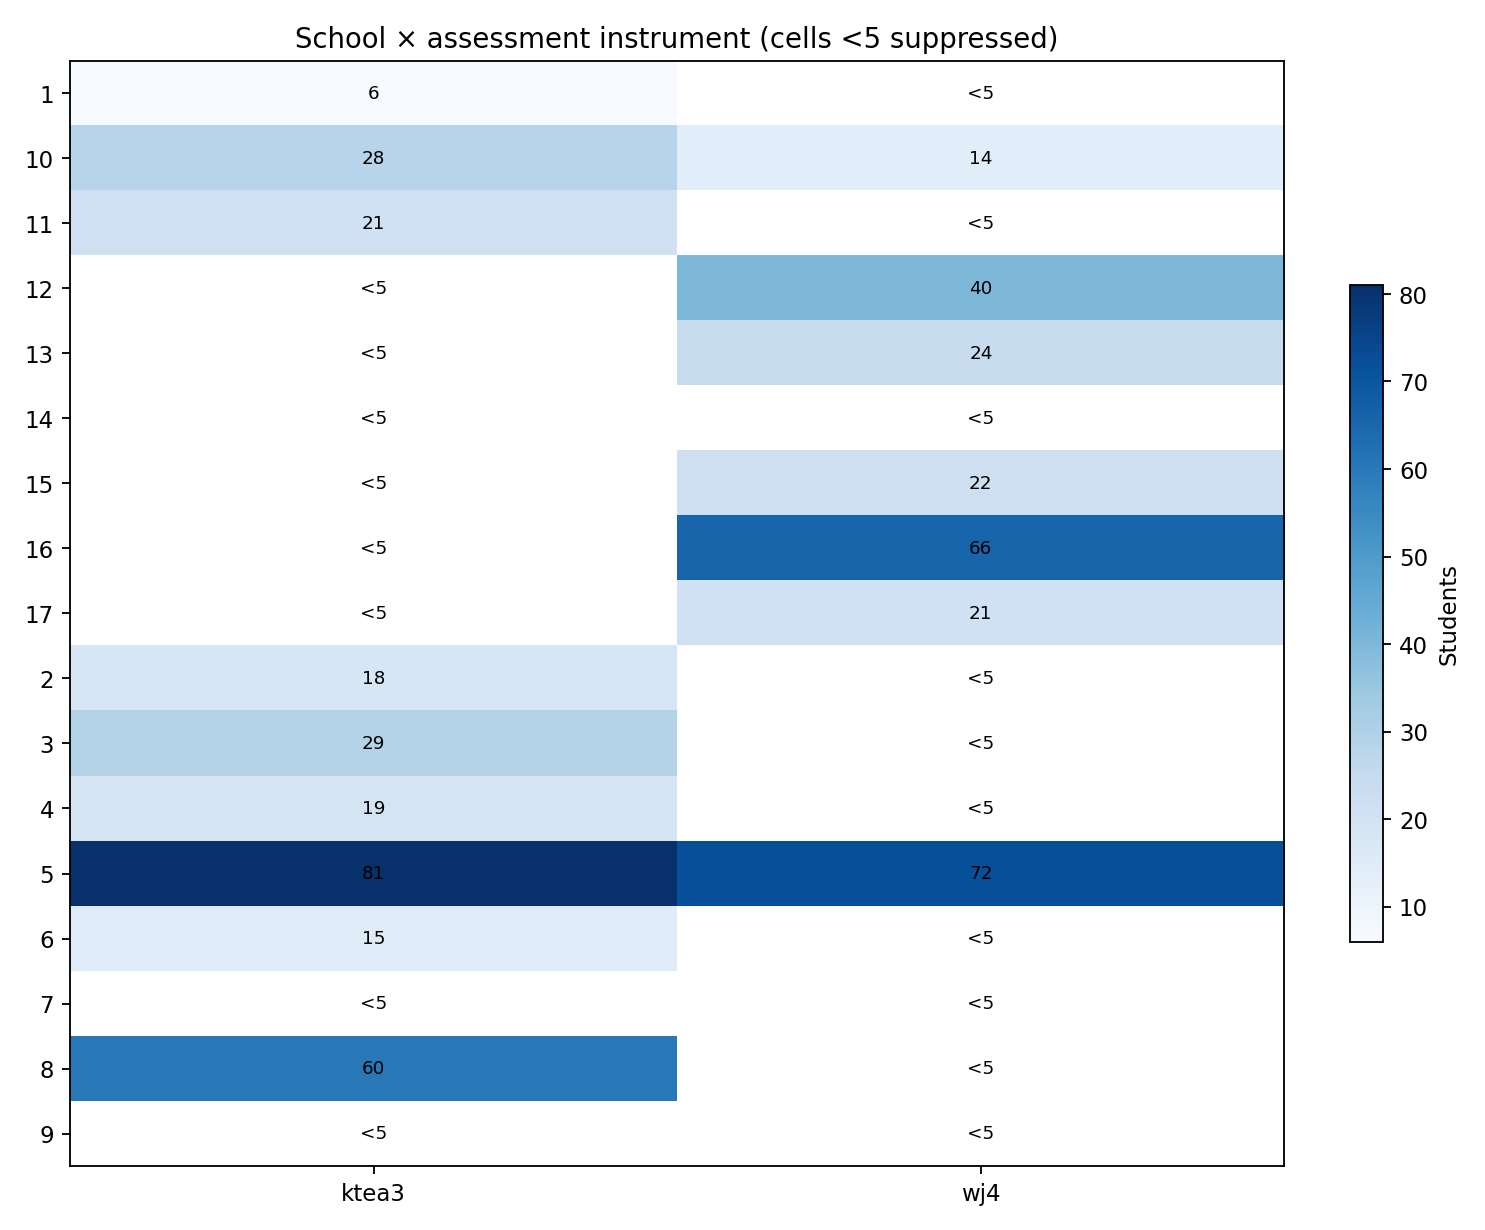

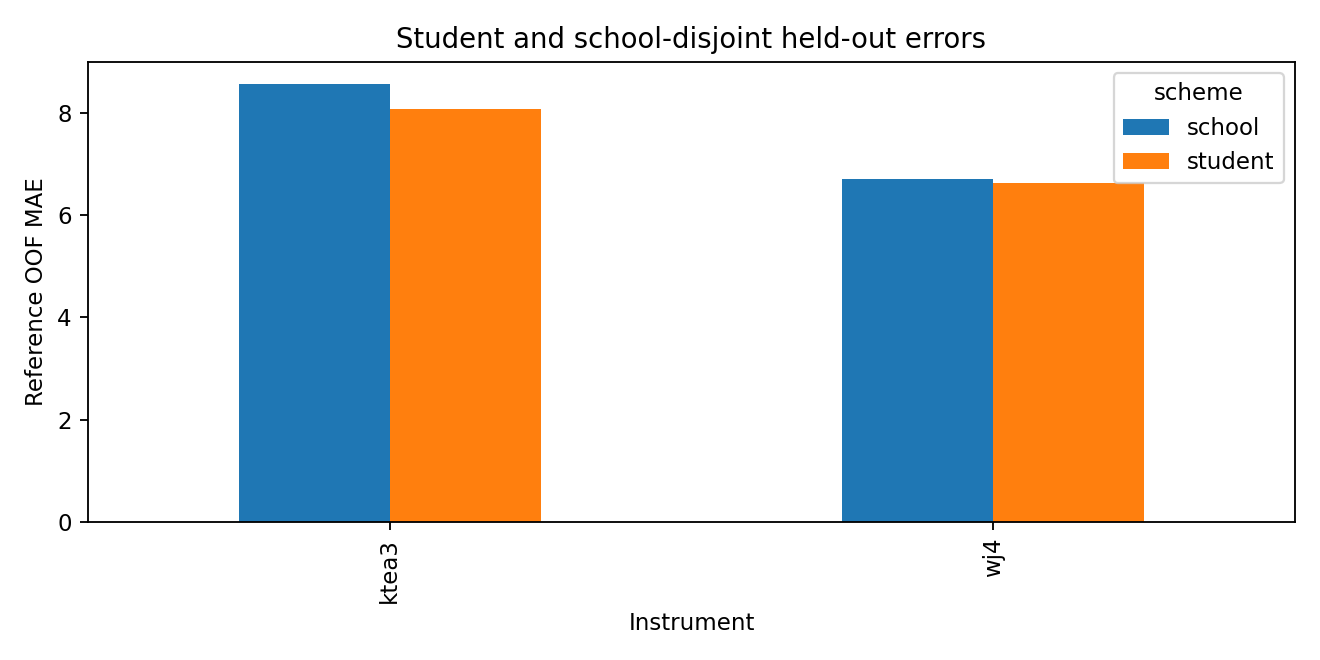

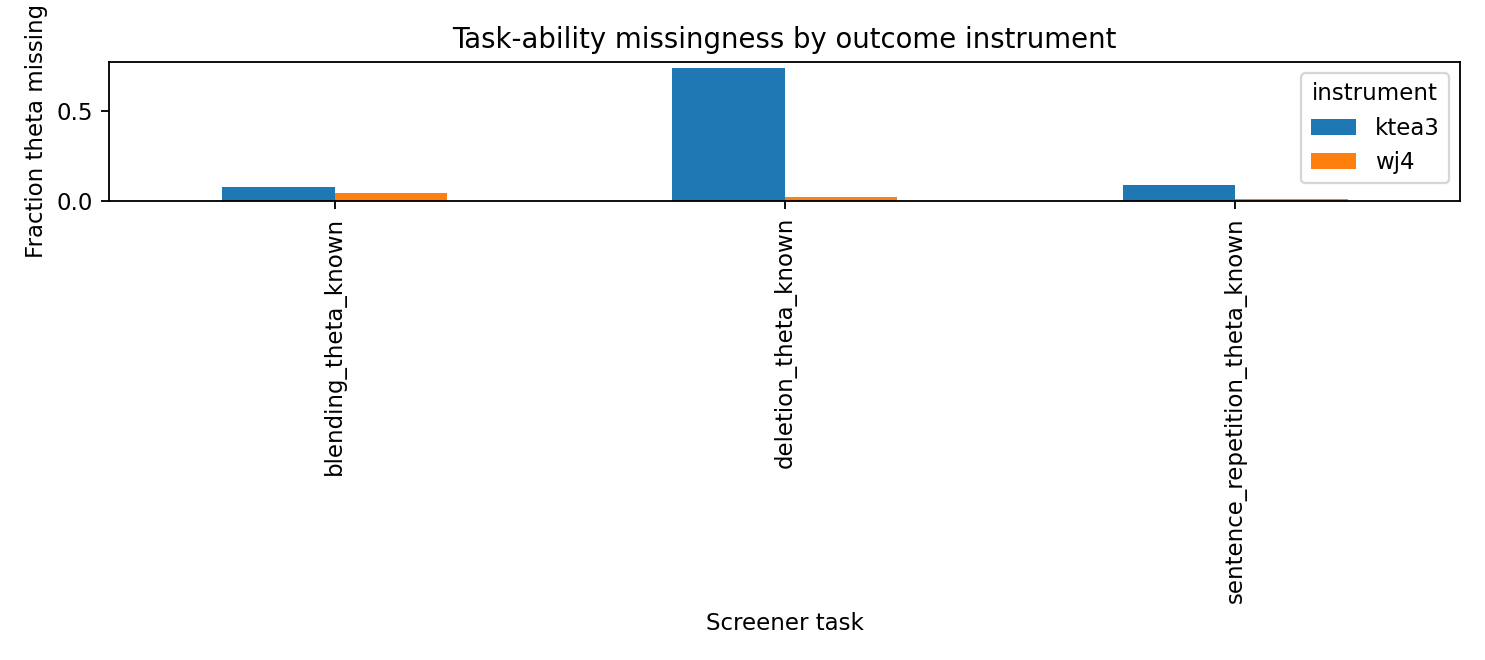

In [23]:
path=OUTPUT_ROOT/"diagnostics"
for filename in ("instrument_transfer_by_repeat.csv","missingness_by_instrument.csv",
                 "task_availability_train_test_coverage_only.csv"):
    print("\n",filename)
    display(pd.read_csv(path/filename).head(14))
print("\nItem feature contract:")
ITEM_CONTRACT=json.loads((path/"item_contract.json").read_text())
display(pd.DataFrame([{"key":k,"value":str(v)[:150]} for k,v in ITEM_CONTRACT.items()]))
for filename in ("01_school_instrument_counts_private.png","02_school_instrument_transfer.png",
                 "03_missingness_by_instrument.png"):
    figure=OUTPUT_ROOT/"figures"/filename
    if figure.exists():display(Image(filename=str(figure)))

## 7. Frozen-fold R² and paired model comparison

Primary selection uses mean of 10-repeat pooled student R², while the gate uses mean paired fold ΔR² on all 50 student folds. Never compare individual folds with different split hashes.

,model,mean_fold_r2,mean_student_pooled_r2,mean_school_pooled_r2,student_mae,student_rmse,mean_fold_delta_r2,corrected_t,win_fraction,school_pooled_delta_r2,gate
0,E00,0.19323,0.19911,0.14736,7.37051,9.95674,NaN,NaN,NaN,NaN,NaN
1,E01,0.19500,0.20141,0.15128,7.33859,9.94244,0.00177,0.20239,0.60,0.00392,HOLD
2,E02,0.19225,0.19828,0.14808,7.31049,9.96189,-0.00098,-0.05306,0.52,0.00072,DROP
3,E03,0.20206,0.20739,0.15814,7.30457,9.90517,0.00883,1.03444,0.72,0.01077,HOLD
4,E04,0.20779,0.21263,0.15602,7.26189,9.87233,0.01456,1.37127,0.88,0.00866,HOLD
5,E05,0.20187,0.20653,0.13899,7.31157,9.91046,0.00864,0.77052,0.66,-0.00837,DIAGNOSTIC_ONLY
6,E06,0.19424,0.19929,0.13211,7.32952,9.95563,0.00101,0.09397,0.48,-0.01525,DIAGNOSTIC_ONLY
7,E07,0.20677,0.21144,0.15465,7.25351,9.87983,0.01355,1.19924,0.84,0.00729,DIAGNOSTIC_ONLY
8,E08,0.20512,0.21005,0.15701,7.28389,9.88852,0.01189,1.29779,0.82,0.00964,DIAGNOSTIC_ONLY
9,E09,0.20731,0.21198,0.15644,7.25721,9.87644,0.01409,1.23506,0.84,0.00907,DIAGNOSTIC_ONLY


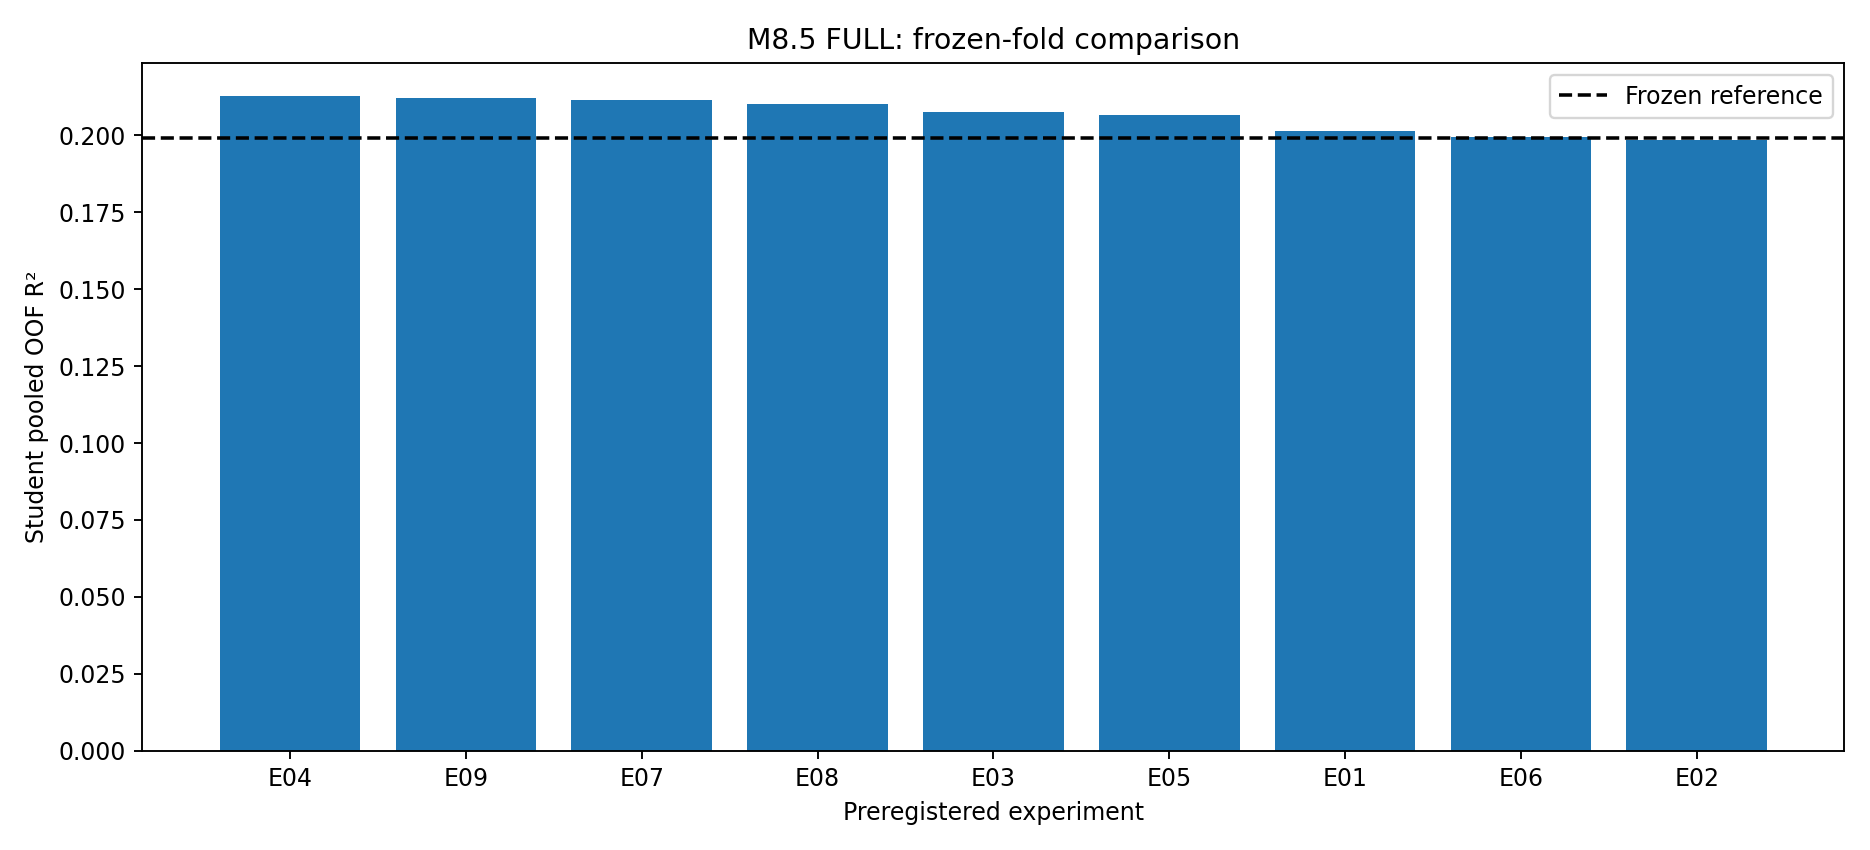

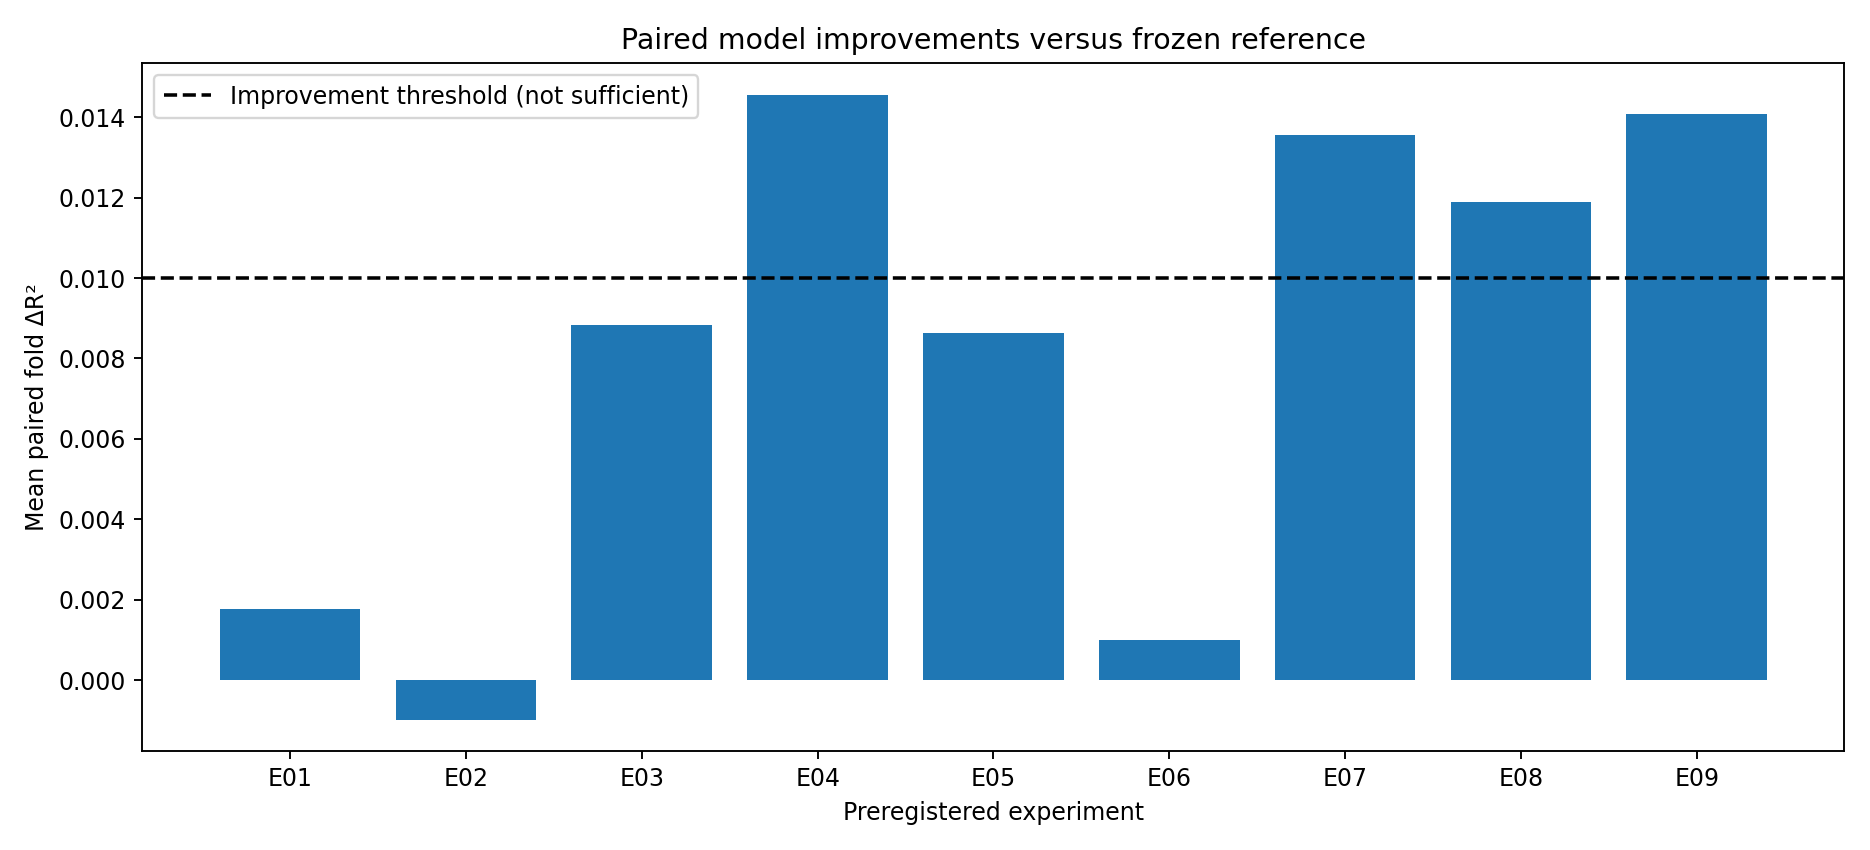

In [24]:
RESULTS=pd.DataFrame(RESULT["model_metrics"])
cols=[c for c in ["model","mean_fold_r2","mean_student_pooled_r2",
                  "mean_school_pooled_r2","student_mae","student_rmse",
                  "mean_fold_delta_r2","corrected_t","win_fraction",
                  "school_pooled_delta_r2","gate"] if c in RESULTS]
display(RESULTS[cols].round(5))
if MODE=="FULL":
    assert all(RESULTS[RESULTS.model!="E00"].n_folds==100)
else:
    print("SCREEN exploratory-only results: no corrected significance or promotion.")
for filename in ("04_candidate_pooled_r2.png","05_paired_delta_r2.png"):
    f=OUTPUT_ROOT/"figures"/filename
    if f.exists():display(Image(filename=str(f)))

## 8. Feature-family ablations and nuisance controls

E04 bundles S2/S3/S4/S5 together. E05–E08 remove one block conditionally. E09 removes screening protocol nuisance proxies (reference duration and sample-rate fields). This does not claim audio is useful.

In [25]:
if MODE=="FULL":
    PAIRS=pd.read_csv(OUTPUT_ROOT/"tables"/"paired_comparison_audit.csv")
    display(PAIRS.round(5))
    print("Explanation only: E05–E09 cannot independently become the chosen model.")
else:
    print("Only FULL has 50-fold corrected paired comparisons.")

,comparison_id,gate,mean_fold_delta_r2,school_pooled_delta_r2,win_fraction,corrected_t,instrument_deltas
0,E01_VS_E00,HOLD,0.00177,0.00392,0.60,0.20239,"{""ktea3"": 0.006272337861060085, ""wj4"": -0.0039..."
1,E02_VS_E00,DROP,-0.00098,0.00072,0.52,-0.05306,"{""ktea3"": 0.011005018295021374, ""wj4"": -0.0194..."
2,E03_VS_E00,HOLD,0.00883,0.01077,0.72,1.03444,"{""ktea3"": 0.014229286763965098, ""wj4"": -0.0009..."
3,E04_VS_E00,HOLD,0.01456,0.00866,0.88,1.37127,"{""ktea3"": 0.012807302954008226, ""wj4"": 0.01484..."
4,E05_VS_E00,DIAGNOSTIC_ONLY,0.00864,-0.00837,0.66,0.77052,"{""ktea3"": 0.008076292367772797, ""wj4"": 0.00649..."
5,E06_VS_E00,DIAGNOSTIC_ONLY,0.00101,-0.01525,0.48,0.09397,"{""ktea3"": -0.004392885240387068, ""wj4"": 0.0073..."
6,E07_VS_E00,DIAGNOSTIC_ONLY,0.01355,0.00729,0.84,1.19924,"{""ktea3"": 0.01299188089723694, ""wj4"": 0.011462..."
7,E08_VS_E00,DIAGNOSTIC_ONLY,0.01189,0.00964,0.82,1.29779,"{""ktea3"": 0.006980567916444813, ""wj4"": 0.01733..."
8,E09_VS_E00,DIAGNOSTIC_ONLY,0.01409,0.00907,0.84,1.23506,"{""ktea3"": 0.013237189417555095, ""wj4"": 0.01247..."
9,E04_VS_E01,DIAGNOSTIC_ONLY,0.01279,0.00474,0.70,1.26542,"{""ktea3"": 0.006534965092948142, ""wj4"": 0.01876..."


Explanation only: E05–E09 cannot independently become the chosen model.


## 9. Formal M0+ decision and optional candidate submission

A new candidate submission is exported **only** when FULL completed all preregistered comparisons and an eligible E01–E04 model passed every gate. Otherwise the exact M8.4 reference remains the M0+ fallback.

In [26]:
display(Markdown((OUTPUT_ROOT/"reports"/"M85_M0PLUS_DECISION.md").read_text()))
if RESULT["decision"]=="PROMOTE":
    f=OUTPUT_ROOT/"submission"/"m0plus_submission.csv"
    print("✓ Candidate prediction file (NOT uploaded):",f)
    manifest=json.loads((OUTPUT_ROOT/"submission"/"submission_manifest.json").read_text())
    print("SHA-256:",manifest["sha256"])
    assert manifest["singleton_raw_pipeline_test"]
    assert manifest["test_permutation_invariance"]
else:
    print("No new challenger submission exported; reference remains available from Phase 0.")

# WildSpeech M8.5 — M0+ Screening Milestone Decision

**Status:** HOLD_REFERENCE
**Execution mode:** FULL
**Reference frozen fold hash:** 6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949ac6f1e6a16e092c9ce1
**Reference OOF SHA-256:** a7ecccb0b647f39ff5363d15117484612edfd081cd9d5496f2d55a4ab59bd05d
**Phase 0 benchmark:** 50-fold R²=0.1932274944, 10-repeat pooled R²=0.1991133687 (executed M8.4).
**New results are not publicly scored and must not be interpreted as leaderboard performance.**

## Scientific hypotheses and compliance
KTEA-3 school-disjoint deterioration and deletion missingness motivated targeted S4 and S5 blocks.
All fitted features are learned on outer-training students; S2 training encodings leave each student's scored attempts out.
Train-only label information is used exclusively for model fits, never prompt difficulty.
School ID and score_status are NEVER predictor columns; chronology-derived features are disabled.

## Frozen evaluation and selection

Reference OOF is loaded from M8.4 and never retrained. Student and school splits are unmodified.
Full gate requires paired Δ mean-fold R²≥+.010, corrected t≥2, ≥60% wins, school pooled Δ≥−.005 and per-instrument Δ≥−.010.
E05–E09 are diagnostic ablations/audits; not independently promoted based on repeated selection over outer folds.

## Preregistered model summaries

| model   |   mean_fold_r2 |   mean_student_pooled_r2 |   mean_school_pooled_r2 |   student_mae |   student_rmse |   n_folds |   mean_fold_delta_r2 |   corrected_t |   win_fraction |   school_pooled_delta_r2 |   mean_student_pooled_delta_r2 | gate            | gate_reason                                                     | instrument_delta_r2                                            |
|:--------|---------------:|-------------------------:|------------------------:|--------------:|---------------:|----------:|---------------------:|--------------:|---------------:|-------------------------:|-------------------------------:|:----------------|:----------------------------------------------------------------|:---------------------------------------------------------------|
| E00     |        0.19323 |                  0.19911 |                 0.14736 |       7.37051 |        9.95674 |       100 |            nan       |     nan       |      nan       |                nan       |                      nan       | nan             | nan                                                             | nan                                                            |
| E01     |        0.19500 |                  0.20141 |                 0.15128 |       7.33859 |        9.94244 |       100 |              0.00177 |       0.20239 |        0.60000 |                  0.00392 |                        0.00230 | HOLD            | Positive improvement but below one or more promotion thresholds | {'ktea3': 0.006272337861060085, 'wj4': -0.003918086176628799}  |
| E02     |        0.19225 |                  0.19828 |                 0.14808 |       7.31049 |        9.96189 |       100 |             -0.00098 |      -0.05306 |        0.52000 |                  0.00072 |                       -0.00083 | DROP            | Failed predeclared generalization veto                          | {'ktea3': 0.011005018295021374, 'wj4': -0.019464968462745445}  |
| E03     |        0.20206 |                  0.20739 |                 0.15814 |       7.30457 |        9.90517 |       100 |              0.00883 |       1.03444 |        0.72000 |                  0.01077 |                        0.00827 | HOLD            | Positive improvement but below one or more promotion thresholds | {'ktea3': 0.014229286763965098, 'wj4': -0.0009624358113384468} |
| E04     |        0.20779 |                  0.21263 |                 0.15602 |       7.26189 |        9.87233 |       100 |              0.01456 |       1.37127 |        0.88000 |                  0.00866 |                        0.01352 | HOLD            | Positive improvement but below one or more promotion thresholds | {'ktea3': 0.012807302954008226, 'wj4': 0.014847891997348395}   |
| E05     |        0.20187 |                  0.20653 |                 0.13899 |       7.31157 |        9.91046 |       100 |              0.00864 |       0.77052 |        0.66000 |                 -0.00837 |                        0.00742 | DIAGNOSTIC_ONLY | Ablation or nuisance audit; not eligible for promotion          | {'ktea3': 0.008076292367772797, 'wj4': 0.006499190383614639}   |
| E06     |        0.19424 |                  0.19929 |                 0.13211 |       7.32952 |        9.95563 |       100 |              0.00101 |       0.09397 |        0.48000 |                 -0.01525 |                        0.00017 | DIAGNOSTIC_ONLY | Ablation or nuisance audit; not eligible for promotion          | {'ktea3': -0.004392885240387068, 'wj4': 0.007359264113734998}  |
| E07     |        0.20677 |                  0.21144 |                 0.15465 |       7.25351 |        9.87983 |       100 |              0.01355 |       1.19924 |        0.84000 |                  0.00729 |                        0.01232 | DIAGNOSTIC_ONLY | Ablation or nuisance audit; not eligible for promotion          | {'ktea3': 0.01299188089723694, 'wj4': 0.011462872686925784}    |
| E08     |        0.20512 |                  0.21005 |                 0.15701 |       7.28389 |        9.88852 |       100 |              0.01189 |       1.29779 |        0.82000 |                  0.00964 |                        0.01094 | DIAGNOSTIC_ONLY | Ablation or nuisance audit; not eligible for promotion          | {'ktea3': 0.006980567916444813, 'wj4': 0.017337420509187684}   |
| E09     |        0.20731 |                  0.21198 |                 0.15644 |       7.25721 |        9.87644 |       100 |              0.01409 |       1.23506 |        0.84000 |                  0.00907 |                        0.01286 | DIAGNOSTIC_ONLY | Ablation or nuisance audit; not eligible for promotion          | {'ktea3': 0.013237189417555095, 'wj4': 0.012476420203454065}   |

## Observational screening diagnostics

Instrument count: 2. Schools: 17. Observed prompt keys: 178.

## Model decision

No eligible model passed every preregistered gate; frozen M8.4 Ridge remains M0+.

## Risks and remaining work

- Outer repeated-CV corrected t does not adjust for all model-family search.
- School- and instrument-level associations are observational, not causal.
- Submission #2 is generated only for FULL and PROMOTE with raw singleton inference passing.
- The reference fallback is preserved when no candidate is promoted.
- Genuine child-speech features belong to Phase 2/3, not M0+.


No new challenger submission exported; reference remains available from Phase 0.


## 10. Ledger and full execution check

Validate run hashes and private outputs. Changing feature code produces a new run identity; it never silently overwrites the old reference or candidate artifacts.

In [27]:
ledger=pd.read_parquet(OUTPUT_ROOT/"ledger"/"experiments.parquet")
display(ledger[[c for c in ["model_id","status","git_sha","fold_hash","mean_fold_r2","mean_pooled_oof_r2"] if c in ledger]].tail(15))
if MODE=="FULL":
    assert RESULT["completed_all_E01_E09"] and RESULT["decision"] in ("PROMOTE","HOLD_REFERENCE")
print("Frozen M8.4 split hash preserved:",RESULT["fold_hash"]==EXPECTED_FOLD_HASH)
print("Report and private results:",OUTPUT_ROOT/"reports")

,model_id,status,git_sha,fold_hash,mean_fold_r2,mean_pooled_oof_r2
3,E04,COMPLETE,996daefffd2ddb4bbdce83704e3748b7b6c0ebb6,6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949a...,0.188568,0.200704
4,E05,COMPLETE,996daefffd2ddb4bbdce83704e3748b7b6c0ebb6,6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949a...,0.187497,0.197540
5,E06,COMPLETE,996daefffd2ddb4bbdce83704e3748b7b6c0ebb6,6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949a...,0.180365,0.191491
6,E07,COMPLETE,996daefffd2ddb4bbdce83704e3748b7b6c0ebb6,6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949a...,0.187685,0.199703
7,E08,COMPLETE,996daefffd2ddb4bbdce83704e3748b7b6c0ebb6,6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949a...,0.188974,0.200366
8,E09,COMPLETE,996daefffd2ddb4bbdce83704e3748b7b6c0ebb6,6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949a...,0.190916,0.202915
9,E01,COMPLETE,996daefffd2ddb4bbdce83704e3748b7b6c0ebb6,6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949a...,0.194998,0.201410
10,E02,COMPLETE,996daefffd2ddb4bbdce83704e3748b7b6c0ebb6,6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949a...,0.192248,0.198279
11,E03,COMPLETE,996daefffd2ddb4bbdce83704e3748b7b6c0ebb6,6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949a...,0.202059,0.207387
12,E04,COMPLETE,996daefffd2ddb4bbdce83704e3748b7b6c0ebb6,6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949a...,0.207786,0.212631


Frozen M8.4 split hash preserved: True
Report and private results: /content/drive/MyDrive/WildSpeech_M85/m0plus/reports


## 11. Phase 1 handoff

- **PROMOTE:** freeze the submitted M0+ model and its SHA; use it as the compulsory base for future genuine-speech experiments.
- **HOLD_REFERENCE:** preserve the original 14-feature Ridge reference; the M0+ experiment remains scientifically useful even without a gain.
- **SCREEN_EXPLORATORY:** complete the 100-fold FULL protocol before making conclusions.

The next milestone is Phase 2 speech extraction on separate GPU caches, with per-clip frozen-model outputs and no training on test rows.